# Notebook 03 — Chord Classification

**Project:** Air Guitar CS249R (Software-Only ML Architecture)

This notebook trains a supervised Deep Learning model mapping normalized static hand landmarks to 13 guitar chords.

### Methodology:
1. Load processed chord features from `dataset/processed/chord_features.csv`.
2. Baseline Benchmark: Train Random Forest / Logistic Regression classifier.
3. Neural Network Classifier: Train Deep MLP in TensorFlow/Keras with Dropout and BatchNormalization.
4. Evaluation on held-out test set: Precision, Recall, F1-Score, Confusion Matrix.
5. Plot training/validation loss and accuracy curves.
6. Save best trained model and artifacts to `models/chord_classifier/`.

In [11]:
# 1. Imports and Dataset Loading
import sys
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import joblib

import tensorflow as tf
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

ROOT_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from src.config import PROCESSED_CHORD_CSV, CHORD_MODEL_DIR, CHORD_MODEL_PATH, SUPPORTED_CHORDS

df = pd.read_csv(PROCESSED_CHORD_CSV)
print(f'Loaded {len(df)} chord samples.')
feat_cols = [c for c in df.columns if c not in ('session_id', 'label', 'label_encoded')]
X = df[feat_cols].values.astype(np.float32)
y = df['label_encoded'].values.astype(np.int32)
print(f'Feature dimension: {X.shape[1]}')

Loaded 871 chord samples.
Feature dimension: 98


## 2. Train / Test Split by Session (Non-Leakage)

Partitioning by session guarantees that frames from the same recording are never split between train and test.

In [12]:
# 2. Train / Test Split
# Check if session group split produces a balanced test set with representative classes
use_group_split = False
if df['session_id'].nunique() >= 4:
    gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
    tr_idx, te_idx = next(gss.split(X, y, groups=df['session_id']))
    # Validate that test set is non-trivial and contains representative classes
    if len(te_idx) >= 0.15 * len(X) and len(np.unique(y[te_idx])) >= 0.7 * len(np.unique(y)):
        X_train, X_test = X[tr_idx], X[te_idx]
        y_train, y_test = y[tr_idx], y[te_idx]
        use_group_split = True

if not use_group_split:
    min_class_count = pd.Series(y).value_counts().min()
    strat = y if min_class_count >= 2 else None
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42, stratify=strat
    )

print(f'Train samples: {len(X_train)}, Test samples: {len(X_test)}')
print(f'Unique classes in train: {len(np.unique(y_train))}, in test: {len(np.unique(y_test))}')

Train samples: 696, Test samples: 175
Unique classes in train: 13, in test: 13


## 3. Baseline Classifier Benchmark

Evaluate a Random Forest benchmark prior to deep learning.

In [13]:
# 3. Random Forest Baseline
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_preds = rf.predict(X_test)
rf_acc = accuracy_score(y_test, rf_preds)
print(f'Random Forest Baseline Accuracy: {rf_acc:.2%}')

# Resolve class names dynamically based on present classes
enc_file = CHORD_MODEL_DIR / 'label_encoder.joblib'
if enc_file.exists():
    enc = joblib.load(enc_file)
    class_names_map = {idx: name for idx, name in enumerate(enc.classes_)}
else:
    class_names_map = {idx: name for idx, name in enumerate(SUPPORTED_CHORDS)}

present_labels = sorted(list(set(y_test) | set(rf_preds)))
present_names = [class_names_map.get(i, str(i)) for i in present_labels]
print(classification_report(y_test, rf_preds, labels=present_labels, target_names=present_names, zero_division=0))

Random Forest Baseline Accuracy: 100.00%
              precision    recall  f1-score   support

           a       1.00      1.00      1.00        15
          am       1.00      1.00      1.00        10
           b       1.00      1.00      1.00        13
          bm       1.00      1.00      1.00        14
           c       1.00      1.00      1.00        18
          cm       1.00      1.00      1.00        17
           d       1.00      1.00      1.00        14
          dm       1.00      1.00      1.00        12
           e       1.00      1.00      1.00        12
          em       1.00      1.00      1.00        13
           f       1.00      1.00      1.00        11
           g       1.00      1.00      1.00        13
          gm       1.00      1.00      1.00        13

    accuracy                           1.00       175
   macro avg       1.00      1.00      1.00       175
weighted avg       1.00      1.00      1.00       175



## 4. Deep Learning MLP Architecture & Training

Train Keras Neural Network with early stopping and checkpointing.

In [15]:
# 4. Build and Train Keras MLP
# Determine output dimension based on label encoder
enc_file = CHORD_MODEL_DIR / 'label_encoder.joblib'
if enc_file.exists():
    enc = joblib.load(enc_file)
    num_classes = len(enc.classes_)
else:
    num_classes = max(int(np.max(y)) + 1, len(SUPPORTED_CHORDS))

mlp_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X.shape[1],)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.25),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.20),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(num_classes, activation='softmax')
])

mlp_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint(str(CHORD_MODEL_PATH), monitor='val_accuracy', save_best_only=True)
]

history = mlp_model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=16,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/50
35/35 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.3363 - loss: 2.0408 - val_accuracy: 0.0714 - val_loss: 2.3572
Epoch 2/50
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7644 - loss: 1.0078 - val_accuracy: 0.3786 - val_loss: 1.9886
Epoch 3/50
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8597 - loss: 0.5507 - val_accuracy: 0.4786 - val_loss: 1.5540
Epoch 4/50
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8741 - loss: 0.3772 - val_accuracy: 0.5786 - val_loss: 1.1914
Epoch 5/50
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9029 - loss: 0.2873 - val_accuracy: 0.8500 - val_loss: 0.7214
Epoch 6/50
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9155 - loss: 0.2354 - val_accuracy: 0.8643 - val_loss: 0.5226
Epoch 7/50
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9281 - loss: 0.2034 - val_accuracy: 0.8643 - val_loss: 0.4913
Epoch 8/50
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9155 - loss: 0.2289 - val_accuracy: 0.8643 - val_

## 5. Evaluation, Learning Curves, and Confusion Matrix

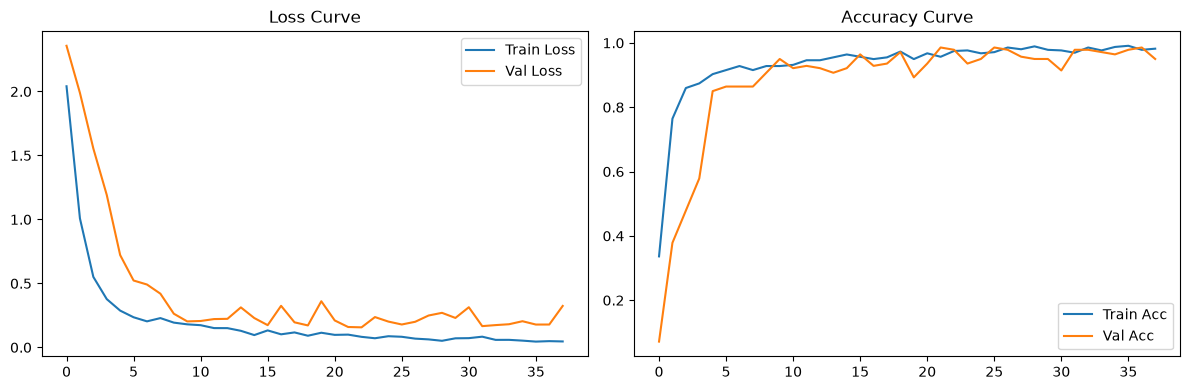

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
Final Test Set Accuracy: 96.57%
              precision    recall  f1-score   support

           a       1.00      0.80      0.89        15
          am       1.00      1.00      1.00        10
           b       0.81      1.00      0.90        13
          bm       0.82      1.00      0.90        14
           c       1.00      1.00      1.00        18
          cm       1.00      1.00      1.00        17
           d       1.00      0.93      0.96        14
          dm       1.00      0.83      0.91        12
           e       1.00      1.00      1.00        12
          em       1.00      1.00      1.00        13
           f       1.00      1.00      1.00        11
           g       1.00      1.00      1.00        13
          gm       1.00      1.00      1.00        13

    accuracy                           0.97       175
   macro avg       0.97      0.97      0.97       175
weighted avg       0.97      0.97      0.97       175



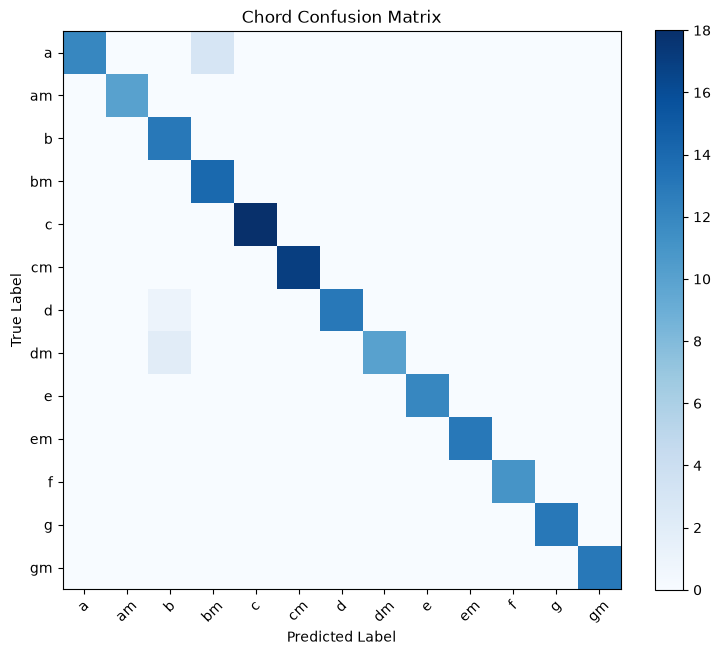

Model exported to C:\Users\piyus\Desktop\ds cp airguitar\models\chord_classifier\chord_classifier.keras


In [16]:
# 5. Plot curves and evaluate test set
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
if 'val_loss' in history.history:
    plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss Curve')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Train Acc')
if 'val_accuracy' in history.history:
    plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title('Accuracy Curve')
plt.legend()
plt.tight_layout()
plt.show()

# Final Test Set Evaluation
mlp_probs = mlp_model.predict(X_test)
mlp_preds = np.argmax(mlp_probs, axis=1)
mlp_acc = accuracy_score(y_test, mlp_preds)
print(f'Final Test Set Accuracy: {mlp_acc:.2%}')

present_labels_mlp = sorted(list(set(y_test) | set(mlp_preds)))
present_names_mlp = [class_names_map.get(i, str(i)) for i in present_labels_mlp]
print(classification_report(y_test, mlp_preds, labels=present_labels_mlp, target_names=present_names_mlp, zero_division=0))

# Confusion Matrix
cm = confusion_matrix(y_test, mlp_preds, labels=present_labels_mlp)
plt.figure(figsize=(max(5, len(present_names_mlp) * 0.6), max(4, len(present_names_mlp) * 0.5)))
plt.imshow(cm, cmap='Blues')
plt.title('Chord Confusion Matrix')
plt.colorbar()
tick_marks = np.arange(len(present_names_mlp))
plt.xticks(tick_marks, present_names_mlp, rotation=45)
plt.yticks(tick_marks, present_names_mlp)
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.show()

# Save finalized model
mlp_model.save(str(CHORD_MODEL_PATH))
print(f'Model exported to {CHORD_MODEL_PATH}')